Analizar la relación entre categorías, best-sellers, precios y valoraciones en Amazon UK, y traducir los resultados en conclusiones de negocio.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, pearsonr, spearmanr, probplot

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

FILE_PATH = "amz_uk_price_prediction_dataset.csv"  # Cambia el nombre si es necesario
df = pd.read_csv(FILE_PATH)

print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")
display(df.head())

Filas: 2,443,651
Columnas: 9


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big vibrant sound Wi-Fi and Bluetooth smart speaker wi...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth Speaker with 15-Hour Playtime, 66-Foot Bluetooth ...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big vibrant sound Wi-Fi and Bluetooth smart speaker wi...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 release) | Bigger vibrant sound Wi-Fi and Bluetooth sm...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-Fi and Bluetooth smart speaker with Alexa | Charcoal,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [2]:
print("Columnas disponibles:")
print(df.columns.tolist())

display(df.info())
display(df.isna().sum().sort_values(ascending=False).head(15))

Columnas disponibles:
['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']
<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 495.8 MB


None

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

El ejercicio utiliza category, isBestSeller, price y stars. Convertimos price y stars a formato numérico por seguridad. En los análisis se excluirán valores ausentes de las variables implicadas, sin eliminar filas innecesariamente de todo el dataset.

In [3]:
required_columns = ["category", "isBestSeller", "price", "stars"]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(
        f"Faltan estas columnas en el CSV: {missing_columns}. "
        f"Columnas disponibles: {df.columns.tolist()}"
    )

df["price"] = pd.to_numeric(df["price"], errors="coerce")
df["stars"] = pd.to_numeric(df["stars"], errors="coerce")

print("Valores únicos de isBestSeller:")
print(df["isBestSeller"].value_counts(dropna=False))


Valores únicos de isBestSeller:
isBestSeller
False    2435671
True        7980
Name: count, dtype: int64


Este bloque de código sirve para comprobar que el dataset tiene las columnas necesarias, convertir los precios y las valoraciones a números y revisar los valores de isBestSeller.

Parte 1 — Best-seller trends across product categories

1.1. Tabla de contingencia y proporción de best-sellers


La tabla de contingencia cuenta productos best-seller y no best-seller por categoría. Para comparar categorías de tamaños distintos, calculamos también la proporción dentro de cada categoría.

Este código busca Qué categorías de productos de Amazon UK tienen una mayor proporción de productos Best Seller

In [4]:
best_seller_data = df[["category", "isBestSeller"]].dropna().copy()

best_seller_table = pd.crosstab(
    best_seller_data["category"],
    best_seller_data["isBestSeller"]
)

display(best_seller_table)

# Proporción dentro de cada categoría
best_seller_proportion = best_seller_table.div(
    best_seller_table.sum(axis=1), axis=0
)

# Identificar la columna que representa True, aunque el tipo importado varíe
true_columns = [
    col for col in best_seller_proportion.columns
    if str(col).strip().lower() in ["true", "1", "yes"]
]

if true_columns:
    bestseller_col = true_columns[0]
    best_seller_rate = (
        best_seller_proportion[bestseller_col]
        .sort_values(ascending=False)
        .rename("best_seller_rate")
    )
    display((best_seller_rate.head(15) * 100).round(2).to_frame("Best-sellers (%)"))
else:
    print("No se ha detectado automáticamente la columna True. Revisa los valores de isBestSeller.")
    display(best_seller_proportion.head())

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


,Best-sellers (%)
category,
Grocery,5.81
Smart Home Security & Lighting,5.77
Health & Personal Care,5.77
Mobile Phone Accessories,4.25
Power & Hand Tools,3.53
"Billiard, Snooker & Pool",3.21
Pet Supplies,3.02
Home Brewing & Wine Making,2.85
Mirrors,2.80


1.2. Test chi-cuadrado de independencia

In [5]:
# Chi-cuadrado requiere frecuencias observadas no negativas.
chi2, p_value, dof, expected = chi2_contingency(best_seller_table)

n_obs = best_seller_table.to_numpy().sum()
min_dimension = min(best_seller_table.shape[0] - 1, best_seller_table.shape[1] - 1)

cramers_v = np.sqrt(chi2 / (n_obs * min_dimension)) if min_dimension > 0 else np.nan

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6g}")
print(f"Cramér's V: {cramers_v:.4f}")

if p_value < 0.05:
    print("Conclusión estadística: se rechaza H0; existe evidencia de asociación entre categoría y best-seller.")
else:
    print("Conclusión estadística: no se rechaza H0; no hay evidencia suficiente de asociación.")

if cramers_v < 0.1:
    strength = "débil"
elif cramers_v < 0.3:
    strength = "pequeña a moderada"
elif cramers_v < 0.5:
    strength = "moderada a relativamente fuerte"
else:
    strength = "fuerte"

print(f"Magnitud orientativa de la asociación según Cramér's V: {strength}.")

Chi-square statistic: 36540.2027
Degrees of freedom: 295
P-value: 0
Cramér's V: 0.1223
Conclusión estadística: se rechaza H0; existe evidencia de asociación entre categoría y best-seller.
Magnitud orientativa de la asociación según Cramér's V: pequeña a moderada.


Este bloque realiza el test chi-cuadrado de independencia y calcula la V de Cramér. En el proyecto sirve para responder a dos preguntas:

1. ¿Existe una asociación estadística entre la categoría de un producto y que sea Best Seller?
2. Si existe esa asociación, ¿qué intensidad tiene?

Nota: con muestras grandes, un resultado puede ser estadísticamente significativo aunque la asociación sea pequeña. Cramér's V ayuda a evaluar su magnitud. Si muchas frecuencias esperadas son pequeñas, interpreta el test con cautela.

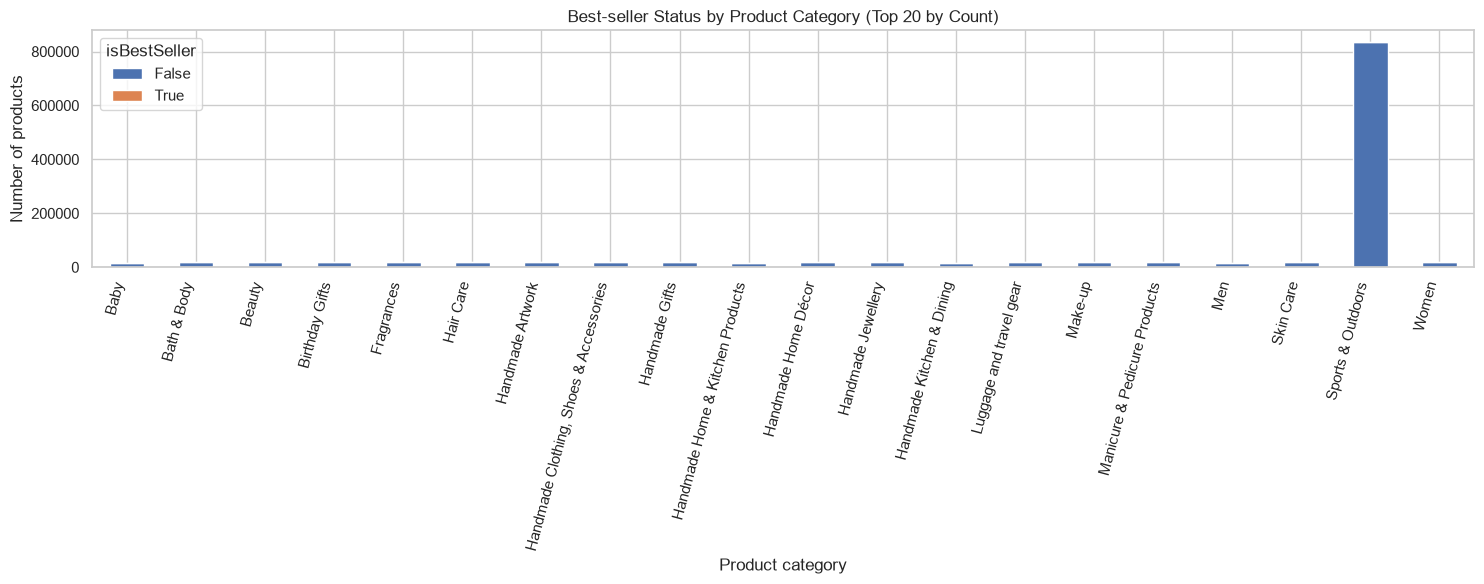

In [8]:
# Mostrar las 20 categorías con más productos para que el gráfico sea legible
top20_bs = best_seller_data["category"].value_counts().head(20).index
table_top20 = best_seller_table.loc[best_seller_table.index.isin(top20_bs)]

table_top20.plot(kind="bar", stacked=True, figsize=(15, 6))

plt.title("Best-seller Status by Product Category (Top 20 by Count)")
plt.xlabel("Product category")
plt.ylabel("Number of products")
plt.xticks(rotation=75, ha="right")
plt.legend(title="isBestSeller")
plt.tight_layout()
plt.show()

El test chi-cuadrado evalúa si la distribución del estado best-seller varía por categoría. Cramér's V indica si la asociación observada tiene una magnitud relevante. Para priorizar categorías, conviene combinar la tasa de best-sellers con el tamaño de la categoría, en lugar de decidir solo por el número absoluto de productos.

Parte 2 — Product prices and ratings across categories and brands

2.0. Eliminar outliers del precio con IQR

Se conservan dos dataframes: df_original para el bonus y df_clean para el análisis principal. El filtro IQR se aplica al precio y no a las valoraciones.

In [9]:
df_original = df.copy()

price_non_null = df_original["price"].dropna()
q1 = price_non_null.quantile(0.25)
q3 = price_non_null.quantile(0.75)
iqr = q3 - q1

lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

df_clean = df_original[
    df_original["price"].isna()
    | df_original["price"].between(lower_limit, upper_limit)
].copy()

# Para análisis de precios se quitarán después los NaN en price.
print(f"Q1: £{q1:.2f}")
print(f"Q3: £{q3:.2f}")
print(f"IQR: £{iqr:.2f}")
print(f"Límite inferior: £{lower_limit:.2f}")
print(f"Límite superior: £{upper_limit:.2f}")
print(f"Filas originales: {len(df_original):,}")
print(f"Filas tras quitar outliers de precio: {len(df_clean):,}")
print(f"Filas eliminadas: {len(df_original) - len(df_clean):,}")
print(f"Porcentaje eliminado: {(len(df_original) - len(df_clean)) / len(df_original):.2%}")

df_price_clean = df_clean.dropna(subset=["category", "price"]).copy()

Q1: £9.99
Q3: £45.99
IQR: £36.00
Límite inferior: £-44.01
Límite superior: £99.99
Filas originales: 2,443,651
Filas tras quitar outliers de precio: 2,115,963
Filas eliminadas: 327,688
Porcentaje eliminado: 13.41%


2.1. Violin plot de precios — 20 categorías más frecuentes

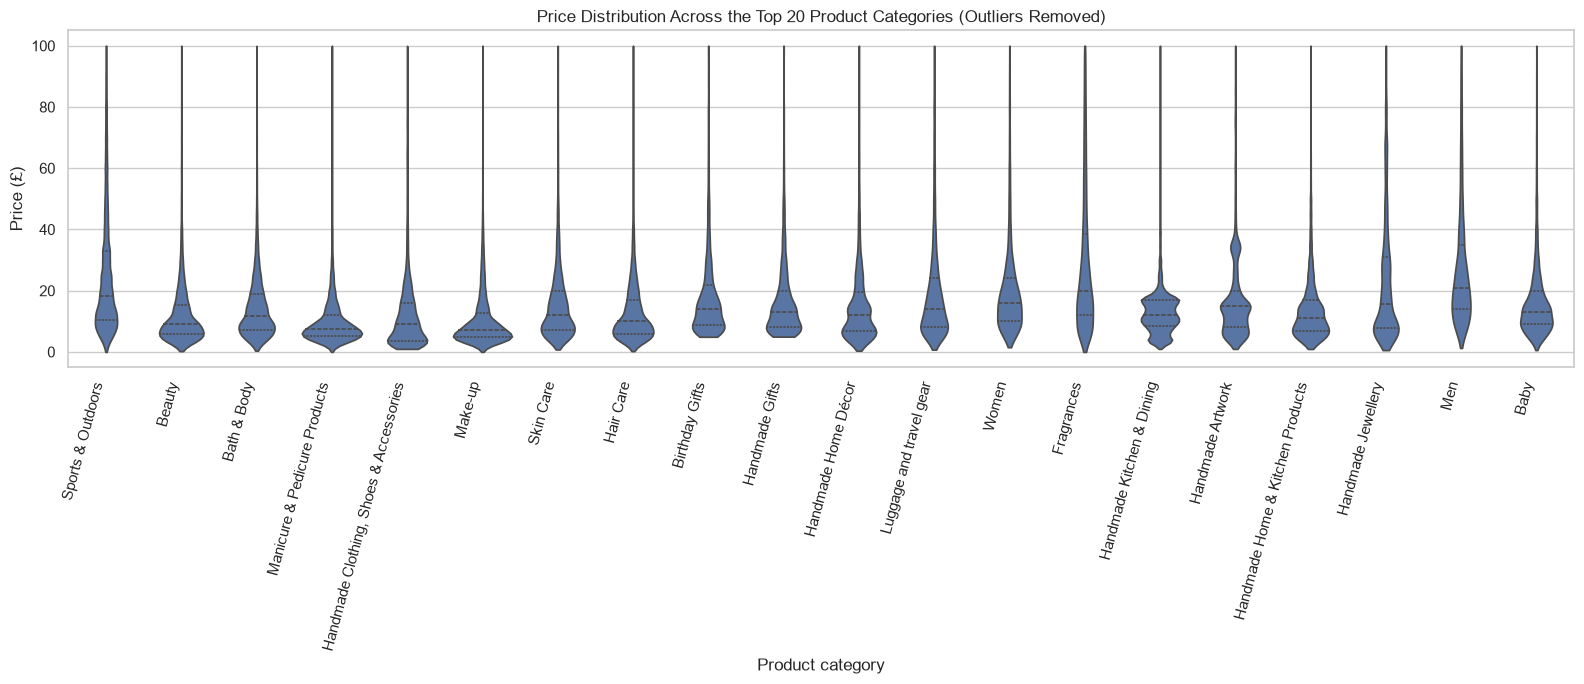

In [ ]:
top20_price_categories = df_price_clean["category"].value_counts().head(20).index
df_price_top20 = df_price_clean[df_price_clean["category"].isin(top20_price_categories)].copy()

plt.figure(figsize=(16, 7))
sns.violinplot(
    data=df_price_top20,
    x="category",
    y="price",
    order=top20_price_categories,
    inner="quartile",
    cut=0
)
plt.title("Price Distribution Across the Top 20 Product Categories (Outliers Removed)")
plt.xlabel("Product category")
plt.ylabel("Price (£)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

Categoría con la mediana de precio más alta (todas las categorías)
La respuesta se calcula sobre todas las categorías, no solo sobre las 20 del gráfico. Ten en cuenta el número de productos por categoría: una mediana alta basada en pocos productos puede no ser representativa.

In [ ]:
price_category_stats = (df_price_clean.groupby("category")["price"].agg(product_count="count", mean_price="mean", median_price="median").sort_values("median_price", ascending=False))

display(price_category_stats.head(15))

highest_median_category = price_category_stats["median_price"].idxmax()

highest_median_value = price_category_stats.loc[highest_median_category, "median_price"]

highest_median_n = price_category_stats.loc[highest_median_category, "product_count"]

print(
    f"Mayor mediana de precio: {highest_median_category} "
    f"(£{highest_median_value:.2f}; n={highest_median_n:,})."
)

,product_count,mean_price,median_price
category,,,
Desktop PCs,169,66.915562,74.00
Boxing Shoes,3873,67.417803,69.79
Tablets,4638,66.552971,69.00
Graphics Cards,57,65.103509,68.54
Motherboards,74,68.772432,67.92
Made in Italy Handmade,1561,56.398398,64.00
Digital Frames,310,60.745129,63.90
Streaming Clients,1692,60.241803,62.68
Golf Shoes,4493,55.361627,62.39


Mayor mediana de precio: Desktop PCs (£74.00; n=169).


2.2. Gráfico de barras — precio medio de las 10 categorías más frecuentes

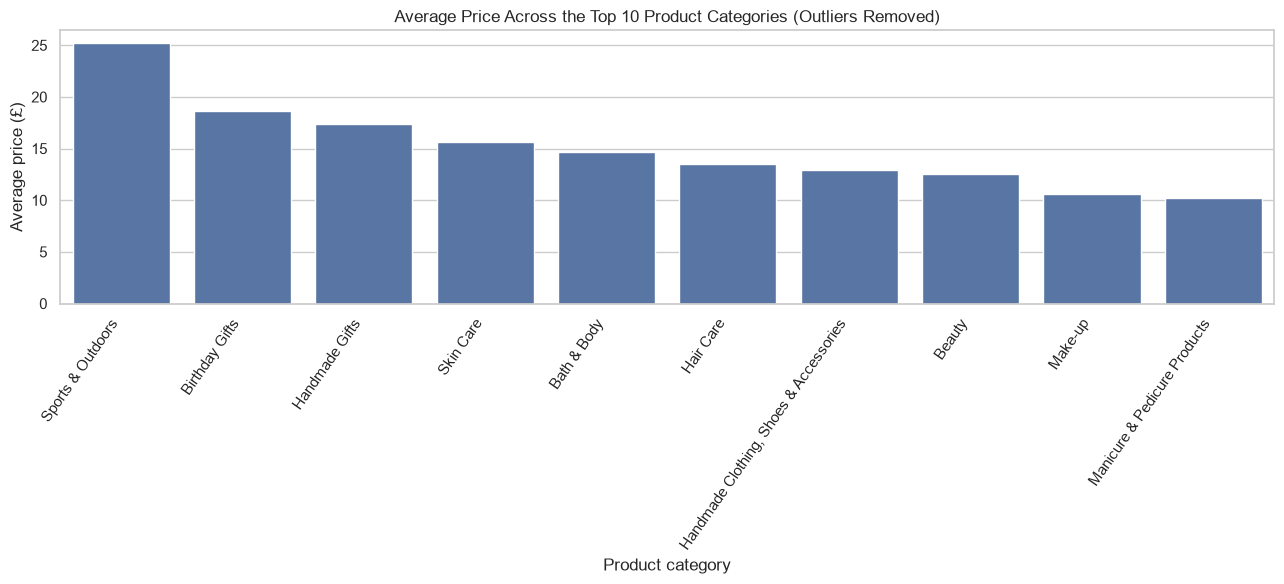

,mean_price
category,
Sports & Outdoors,25.17
Birthday Gifts,18.60
Handmade Gifts,17.40
Skin Care,15.65
Bath & Body,14.68
Hair Care,13.46
"Handmade Clothing, Shoes & Accessories",12.96
Beauty,12.52
Make-up,10.61


In [14]:
top10_price_categories = df_price_clean["category"].value_counts().head(10).index
df_price_top10 = df_price_clean[
    df_price_clean["category"].isin(top10_price_categories)
].copy()

mean_price_top10 = (
    df_price_top10.groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(13, 6))
sns.barplot(
    x=mean_price_top10.index,
    y=mean_price_top10.values
)
plt.title("Average Price Across the Top 10 Product Categories (Outliers Removed)")
plt.xlabel("Product category")
plt.ylabel("Average price (£)")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()
plt.show()

display(mean_price_top10.to_frame("mean_price").round(2))

Categoría con el precio medio más alto (todas las categorías)

El gráfico anterior se limita a las 10 categorías más frecuentes por claridad visual. Esta tabla responde a la pregunta para todas las categorías.

In [15]:
highest_mean_category = price_category_stats["mean_price"].idxmax()

highest_mean_value = price_category_stats.loc[highest_mean_category, "mean_price"]

highest_mean_n = price_category_stats.loc[highest_mean_category, "product_count"]

print(
    f"Mayor precio medio: {highest_mean_category} "
    f"(£{highest_mean_value:.2f}; n={highest_mean_n:,})."
)
display(price_category_stats.sort_values("mean_price", ascending=False).head(15))

Mayor precio medio: Motherboards (£68.77; n=74).


,product_count,mean_price,median_price
category,,,
Motherboards,74,68.772432,67.920
Boxing Shoes,3873,67.417803,69.790
Desktop PCs,169,66.915562,74.000
Tablets,4638,66.552971,69.000
Graphics Cards,57,65.103509,68.540
Digital Frames,310,60.745129,63.900
Streaming Clients,1692,60.241803,62.680
Hockey Shoes,221,60.094796,57.800
Computer Cases,173,58.339884,54.990


2.3 Box plots de valoraciones — 10 categorías más frecuentes

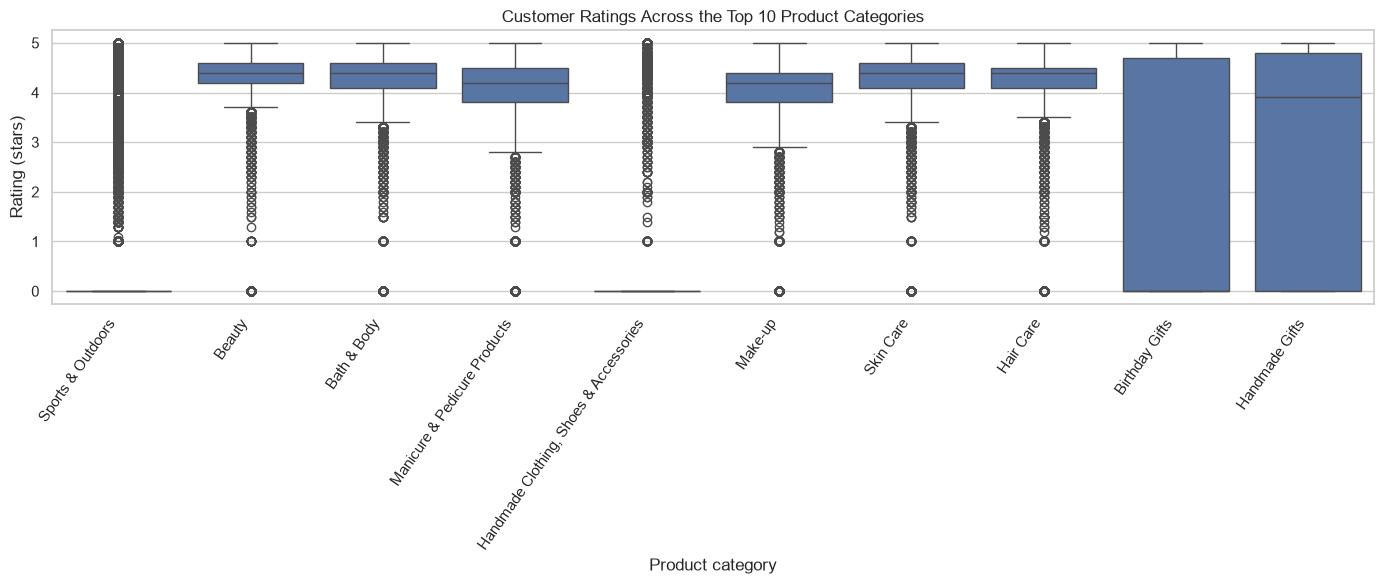

In [16]:
df_ratings_clean = df_clean.dropna(subset=["category", "stars"]).copy()

top10_rating_categories = df_ratings_clean["category"].value_counts().head(10).index
df_rating_top10 = df_ratings_clean[
    df_ratings_clean["category"].isin(top10_rating_categories)
].copy()

plt.figure(figsize=(14, 6))
sns.boxplot(
    data=df_rating_top10,
    x="category",
    y="stars",
    order=top10_rating_categories
)
plt.title("Customer Ratings Across the Top 10 Product Categories")
plt.xlabel("Product category")
plt.ylabel("Rating (stars)")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()
plt.show()

Categoría con la mediana de valoración más alta (todas las categorías)

In [17]:
rating_category_stats = (
    df_ratings_clean.groupby("category")["stars"]
    .agg(product_count="count", mean_stars="mean", median_stars="median")
    .sort_values("median_stars", ascending=False)
)

display(rating_category_stats.head(15))

highest_median_rating_category = rating_category_stats["median_stars"].idxmax()
highest_median_rating = rating_category_stats.loc[highest_median_rating_category, "median_stars"]
highest_rating_n = rating_category_stats.loc[highest_median_rating_category, "product_count"]

print(
    f"Mayor mediana de estrellas: {highest_median_rating_category} "
    f"({highest_median_rating:.2f} estrellas; n={highest_rating_n:,})."
)

,product_count,mean_stars,median_stars
category,,,
Computer Memory,211,4.299526,4.7
"Beer, Wine & Spirits",9271,4.140265,4.6
Building & Construction Toys,8685,3.988440,4.6
Office Paper Products,9090,4.430000,4.6
Kids' Play Figures,9377,4.172838,4.6
Laptop Accessories,250,4.449600,4.6
Hobbies,9065,4.189597,4.6
Luxury Food & Drink,657,4.544140,4.6
Soft Toys,9222,3.793440,4.5


Mayor mediana de estrellas: Computer Memory (4.70 estrellas; n=211).


Parte 3 — Relationship between product prices and ratings

3.1. Correlación entre precio y estrellas

Pearson mide la relación lineal; Spearman mide la relación monótona basada en rangos y puede ser útil cuando los precios son asimétricos.

In [18]:
price_rating = df_clean[["price", "stars"]].dropna().copy()

pearson_r, pearson_p = pearsonr(price_rating["price"], price_rating["stars"])
spearman_r, spearman_p = spearmanr(price_rating["price"], price_rating["stars"])

print(f"N usado: {len(price_rating):,}")
print(f"Pearson r: {pearson_r:.4f}")
print(f"Pearson p-value: {pearson_p:.6g}")
print(f"Spearman rho: {spearman_r:.4f}")
print(f"Spearman p-value: {spearman_p:.6g}")

if pearson_p < 0.05:
    print("Pearson: evidencia estadística de una correlación lineal distinta de cero (α = 0.05).")
else:
    print("Pearson: no hay evidencia estadística suficiente de correlación lineal (α = 0.05).")

if abs(pearson_r) < 0.1:
    print("Magnitud Pearson: muy débil o prácticamente nula.")
elif abs(pearson_r) < 0.3:
    print("Magnitud Pearson: débil.")
elif abs(pearson_r) < 0.5:
    print("Magnitud Pearson: moderada.")
else:
    print("Magnitud Pearson: relativamente fuerte o fuerte.")

N usado: 2,115,963
Pearson r: -0.0777
Pearson p-value: 0
Spearman rho: -0.0668
Spearman p-value: 0
Pearson: evidencia estadística de una correlación lineal distinta de cero (α = 0.05).
Magnitud Pearson: muy débil o prácticamente nula.


3.2. Scatter plot: estrellas y precio

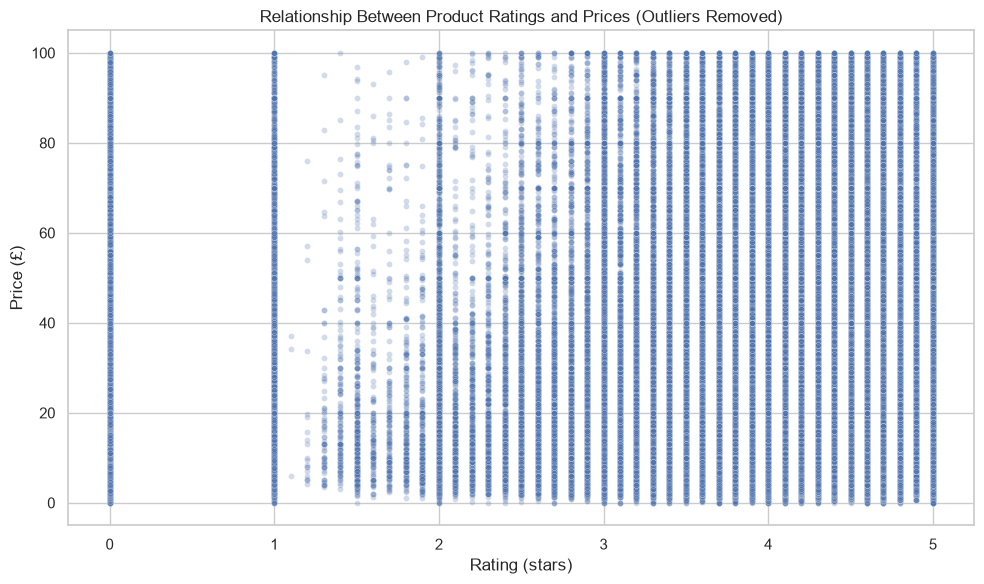

In [19]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=price_rating,
    x="stars",
    y="price",
    alpha=0.25,
    s=18
)
plt.title("Relationship Between Product Ratings and Prices (Outliers Removed)")
plt.xlabel("Rating (stars)")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.show()

Interpretación del QQ plot: si los puntos siguen la línea, los datos se aproximan a una distribución normal. Curvas o desviaciones sistemáticas, especialmente en las colas, indican que los precios se apartan de la normalidad. No es necesario que los precios sean normales para realizar un EDA, pero sí conviene describir su distribución correctamente.

Conclusión de negocio — Parte 3
La correlación permite evaluar si los precios más altos tienden a asociarse con mejores o peores valoraciones. Una correlación débil sugeriría que el precio por sí solo no explica bien las estrellas. Incluso cuando la correlación es significativa, no demuestra que subir el precio cause cambios en la satisfacción.